In [1]:
## download tiny shakespeare dataset for training
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-10-14 13:16:10--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-10-14 13:16:10 (39.3 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [ ]:
#  LOADING GPT2 using hugging fac
from transformers import GPT2LMHeadModel

In [ ]:
model_hf = GPT2LMHeadModel.from_pretrained("gpt2") #124M
sd_hf = model_hf.state_dict()  # state_dict():  return raw tensors

for k,v in sd_hf.items():
  print(k, v.shape)


# transformer.wte.weight torch.Size([50257, 768])  : wte = weight for word token embeddings  , 50257: num of tokens in gpt2 vocab, 768: embedding dimension
# 50257 (Rows): The vocabulary size. This is the total number of unique tokens (words, parts of words, punctuation marks, and special symbols) that the GPT-2 tokenizer recognizes. Every single token has its own dedicated row in this table.
# 768 (Columns): The embedding dimension (n_embd). This is the size of the vector assigned to each token. It represents the number of "features" or dimensions the model uses to understand the meaning of that token in a high-dimensional space
# -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
# wpe = weight for word position embedding   .... 1024:  maximum seq len , 768 : embedding dim
# 1024 (Rows): The maximum sequence length (or block_size). GPT-2 has a fixed context window of 1024 tokens. This means there is a unique position vector for every single position from index 0 up to 1023.
# 768 (Columns): The embedding dimension (n_embd). This matches the size of the token embeddings so they can be combined.

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias 

In [ ]:
sd_hf["transformer.wpe.weight"].view(-1)[:20]

# .view(-1): Flattens the 2D tensor into a single, long 1D tensor containing all elements back-to-back ($1024 \times 768 = 786,432$ total numbers).[:20]: Slices and returns just the first 20 numbers from that flattened sequence.

tensor([-0.0188, -0.1974,  0.0040,  0.0113,  0.0638, -0.1050,  0.0369, -0.1680,
        -0.0491, -0.0565, -0.0025,  0.0135, -0.0042,  0.0151,  0.0166, -0.1381,
        -0.0063, -0.0461,  0.0267, -0.2042])

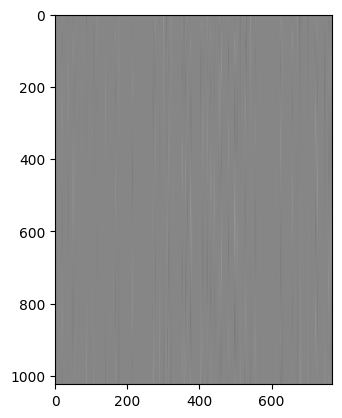

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.imshow(sd_hf["transformer.wpe.weight"],cmap="gray")

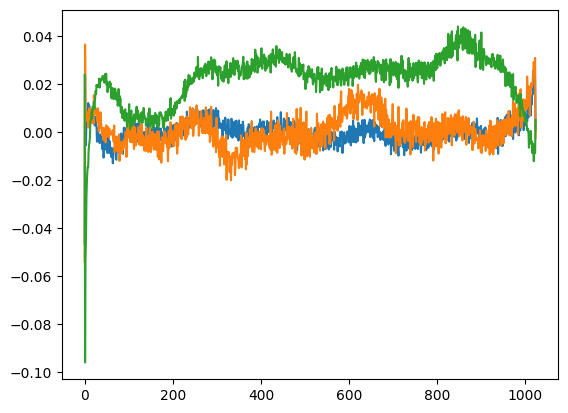

In [ ]:
plt.plot(sd_hf["transformer.wpe.weight"][:,150])
plt.plot(sd_hf["transformer.wpe.weight"][:,200])
plt.plot(sd_hf["transformer.wpe.weight"][:,250])


in original attention is all you need paper, the positional embeddings are initialized and fixed to sinusoid and cosines of different frequencies, but in gpt2 they are parameters and they are trained from scratch.

In [ ]:
from transformers import pipeline,set_seed
generator = pipeline('text-generation',model='gpt2')
set_seed(42)
generator("hello I am a language model", max_length=30,num_return_sequences=5)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': "hello I am a language model, I can understand it. But I can't understand English. Then I understand the rules of the language and also the laws of the language, and that's why I am teaching it. So, you know, the first time I told people that I was going to give the English language to a kid I was really surprised by them and they didn't want to hear that.\n\nAMY GOODMAN: So, let's talk about the English language – you're here now, Amy, and I'm here with you at the U.K.'s Royal Academy of Dramatic Art.\n\nAMY GOODMAN: So, this is the Royal Academy – was this the school where people learned to speak English?\n\nAMY GOODMAN: Yes. This is the Royal Academy of Dramatic Art. It's the oldest institution of higher learning in the world. The first part of the school was set up in 1520. It was the cradle of the British Empire, and it was the first school of education in history. The first English-language school was set up at the Royal Academy of Dramatic Art in 1520.\n\nAMY

## train_gpt2.py

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0

        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))
        att = F.softmax(att,dim=-1)
        y = att @ v
        y = y.transpose(1,2).contiguous().view(B,T,C)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(  # the main container ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around a tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doent have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

    @classmethod
    def from_pretrained(cls,model_type):
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined fro model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])

        return model

# -----------------------------------------------------------------------------------

model = GPT.from_pretrained('gpt2')
print("didn't crash yay!!")

loading weights from pretrained gpt: gpt2


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

didn't crash yay!!


## generating output:

In [1]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here.
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future")
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

    def forward(self, idx):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        return logits


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# -----------------------------------------------------------------------------------

# model = GPT.from_pretrained('gpt2')
# print("didn't crash yay!!")

## let's generate from the model
num_return_sequences = 5
max_length = 30

model = GPT.from_pretrained('gpt2')
model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

loading weights from pretrained gpt: gpt2


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

> Hello, I'm a language model, not a program.

So this morning I started studying for the interview in the lab. This was not
> Hello, I'm a language model, and one of the main things that bothers me when they create languages is how easy it becomes to create something that
> Hello, I'm a language model, and I wrote it off on the grounds that a language model would make me more fluent. But I'm not
> Hello, I'm a language model, I really like languages. I like languages because like, they're good. And the way we talk about languages
> Hello, I'm a language model, a language model I'm using for data modelling. All I did was test the results and then I wrote some


## random initalization instead of importing pretrained parameters of gpt2

model = GPT(GPTConfig())

The output would be random

In [1]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here.
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future")
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

    def forward(self, idx):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        return logits


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# -----------------------------------------------------------------------------------

# model = GPT.from_pretrained('gpt2')
# print("didn't crash yay!!")

# attempt to autodetect the device
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")
## let's generate from the model
num_return_sequences = 5
max_length = 30

# model = GPT.from_pretrained('gpt2')  # importing pretrained weights
# initalizing model from scratch
model = GPT(GPTConfig())  # the output generated on first time would be random
model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
> Hello, I'm a language model, Yuk Exchangethelarton� Universal Java option gorge Santos Includes 1959 vibration protagonists Peg Internet hurts IN occupyingminster scandal vital
> Hello, I'm a language model, Stevenson perpetrator Kath internetpled ALWAYSSt toys Salvationk External mortarcentric Satanicyoutu Passenger Rukanguagestatement saledogs intellectually
> Hello, I'm a language model, ble Judicial civilization Nan hit doub Fantastic petitionerBio Gavin XIII profitability458大Eyflowdemocraticdate songs Rodgers Schultz incent
> Hello, I'm a language model, booth goof pedestriansiostakingulators295>[ proble focusesoutubeiku oversightKid248 motivate galactic src884 inappropriate238Norm
> Hello, I'm a language model, Kwaturated Hard Dream cookie Universal swallowed arrive yielding Ald legit departed extravag protagonists evoke puppORKWIND transmissionYD640 missing


## training_model(gpt)_from_scratch.py

step by step dev

In [8]:
# !wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()
data = text[:1000]
print(data[:100])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You


In [9]:
import tiktoken 
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode(data)
print(tokens[:24])


[5962, 22307, 25, 198, 8421, 356, 5120, 597, 2252, 11, 3285, 502, 2740, 13, 198, 198, 3237, 25, 198, 5248, 461, 11, 2740, 13]


In [ ]:
## we want to process these token sequences and feed them into a transformer and in particular we want to rearrrange these tokens into idx variable, we want an entire batch where each seq is T token and T cant be longer than max_length
## here is how to do it

In [ ]:
import torch
buf = torch.tensor(tokens[:24])
x = buf.view(4,6)    # 4 rows, each row has 6 tokens from the above sequence
print(x)

tensor([[ 5962, 22307,    25,   198,  8421,   356],
        [ 5120,   597,  2252,    11,  3285,   502],
        [ 2740,    13,   198,   198,  3237,    25],
        [  198,  5248,   461,    11,  2740,    13]])


In [ ]:
## code for targets in order to calculate loss
buf = torch.tensor(tokens[:24+1])   # +1 in order to include next token of last(13) token....  (B*T+1)
x = buf[:-1].view(4,6)       # buf[:-1]: take everything upto the last token, but not including the last token
y = buf[1:].view(4,6)
print(x)
print(y)

tensor([[ 5962, 22307,    25,   198,  8421,   356],
        [ 5120,   597,  2252,    11,  3285,   502],
        [ 2740,    13,   198,   198,  3237,    25],
        [  198,  5248,   461,    11,  2740,    13]])
tensor([[22307,    25,   198,  8421,   356,  5120],
        [  597,  2252,    11,  3285,   502,  2740],
        [   13,   198,   198,  3237,    25,   198],
        [ 5248,   461,    11,  2740,    13,   198]])


In [ ]:
## we can see that the y represents next token of each token
## now lets apply this and calculate logits

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

    def forward(self, idx):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        return logits


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

# get a data batch
import tiktoken
enc = tiktoken.get_encoding('gpt2')
with open('input.txt','r',encoding='utf-8') as f:
    text = f.read()
text = text[:1000]
tokens = enc.encode(text)
B , T = 4 , 32
buf = torch.tensor(tokens[:B*T + 1])
x = buf[:-1].view(B,T)
y = buf[1:].view(B,T)


# get logits
model = GPT(GPTConfig())
model.to(device)
logits = model(x.to(device))

print(logits.shape)

import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
torch.Size([4, 32, 50257])


SystemExit: 0

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
# so now we have logits i.e predictions for what comes next, now lets calculate loss

In [16]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

# get a data batch
import tiktoken
enc = tiktoken.get_encoding('gpt2')
with open('input.txt','r',encoding='utf-8') as f:
    text = f.read()
text = text[:1000]
tokens = enc.encode(text)
B , T = 4 , 32
buf = torch.tensor(tokens[:B*T + 1])
x = buf[:-1].view(B,T)
y = buf[1:].view(B,T)

# get logits
model = GPT(GPTConfig())
model.to(device)
logits  , loss = model(x.to(device),y.to(device))

print(loss)

import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
tensor(11.1301, device='cuda:0', grad_fn=<NllLossBackward0>)


SystemExit: 0

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
## the loss is roughly 11

## our vocab size is 50257, at initalization of the network, we would hope that every vocab element is getting roughly a uniform probability so that we may not favour at initalization any token way too much, so we hope that prob of any arbitrary token at initalization is 1/50257=0.000019897, now we can sanity check the loss, (crossentropy loss is just negative log likelihood) so -ln(1/50257)=10.82 ..this is the loss we expect at initalization.... 11 and 10 are much closer.... so it tells us that at initalization our prob dist are roughly diffused, and its a good starting point, so now lets do # optimization , gradient calc (backward()/backprop), print loss  

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

# get a data batch
import tiktoken
enc = tiktoken.get_encoding('gpt2')
with open('input.txt','r',encoding='utf-8') as f:
    text = f.read()
text = text[:1000]
tokens = enc.encode(text)
B , T = 4 , 32
buf = torch.tensor(tokens[:B*T + 1])
buf = buf.to(device)
x = buf[:-1].view(B,T)
y = buf[1:].view(B,T)

# get logits
model = GPT(GPTConfig())
model.to(device)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
for i in range(50):
    optimizer.zero_grad()   # zero the gradients 
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    optimizer.step()  
    print(f"step {i}, loss: {loss.item()}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
step 0, loss: 10.957075119018555
step 1, loss: 6.604362487792969
step 2, loss: 4.263254642486572
step 3, loss: 2.6251490116119385
step 4, loss: 1.5263316631317139
step 5, loss: 0.8631282448768616
step 6, loss: 0.4910031855106354
step 7, loss: 0.2912401556968689
step 8, loss: 0.18358035385608673
step 9, loss: 0.11786052584648132
step 10, loss: 0.07947378605604172
step 11, loss: 0.05946344509720802
step 12, loss: 0.04514303058385849
step 13, loss: 0.03579883277416229
step 14, loss: 0.03046380542218685
step 15, loss: 0.02647210657596588
step 16, loss: 0.022679973393678665
step 17, loss: 0.019456125795841217
step 18, loss: 0.017036300152540207
step 19, loss: 0.015226461924612522
step 20, loss: 0.013765799812972546
step 21, loss: 0.012473635375499725
step 22, loss: 0.011278098449110985
step 23, loss: 0.010184280574321747
step 24, loss: 0.009219789877533913
step 25, loss: 0.008398493751883507
step 26, loss: 0.007713214959949255
step 27, loss: 0.00714306253939867
step 28, l

SystemExit: 0

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
## from loss above, we can see that we are overfitting this single batch and the model is learning this single batch very very well

## we dont want to work with a single batch and overfit it so we need to iterate these x and y and create a dataloader to make sure that we are always getting a fresh batch and that would actually optimize a reasonable objective

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz
    
    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

# get logits
model = GPT(GPTConfig())
model.to(device)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
for i in range(50):
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients 
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    optimizer.step()  
    print(f"step {i}, loss: {loss.item()}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
loaded 338025 tokens
1 epoch = 2640 batches
step 0, loss: 11.107540130615234
step 1, loss: 9.696662902832031
step 2, loss: 8.819008827209473
step 3, loss: 9.087305068969727
step 4, loss: 8.534957885742188
step 5, loss: 8.168149948120117
step 6, loss: 9.006893157958984
step 7, loss: 8.775346755981445
step 8, loss: 8.03952407836914
step 9, loss: 7.8479180335998535
step 10, loss: 8.264505386352539
step 11, loss: 7.124870300292969
step 12, loss: 7.676546573638916
step 13, loss: 7.316226482391357
step 14, loss: 7.473066806793213
step 15, loss: 7.246993064880371
step 16, loss: 7.333544731140137
step 17, loss: 8.2100830078125
step 18, loss: 7.0478291511535645
step 19, loss: 7.703447341918945
step 20, loss: 7.472855567932129
step 21, loss: 7.681099891662598
step 22, loss: 6.228963851928711
step 23, loss: 6.668604850769043
step 24, loss: 6.615322113037109
step 25, loss: 6.284151554107666
step 26, loss: 6.437747478485107
step 27, loss: 7.530484676361084
step 28, loss: 6.958121

SystemExit: 0

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,module):
        if isinstance(module,nn.Linear):
            torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
            elif isinstance(module,nn.Embedding):
                torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

# get logits
model = GPT(GPTConfig())
model.to(device)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
for i in range(50):
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients 
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    optimizer.step()  
    print(f"step {i}, loss: {loss.item()}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

In [1]:
## motivation for scaling(according to gpt2 paper) the residual layers
# standard deviation grows inside the residual stream
x = torch.zeros(768)
n = 100 # e.g 100 layers
for i in range(n):
    x += torch.randn(768)

print(x.std())

NameError: name 'torch' is not defined

In [ ]:
## implementing scaling 

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,module):
        if isinstance(module,nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
            elif isinstance(module,nn.Embedding):
                torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

# get logits
model = GPT(GPTConfig())
model.to(device)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
for i in range(50):
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients 
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    optimizer.step()  
    print(f"step {i}, loss: {loss.item()}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

## Speeding up training (GPU)

In [ ]:
## 1 measuring time

In [7]:

from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
            elif isinstance(model,nn.Embedding):
                torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

# get logits
model = GPT(GPTConfig())
model.to(device)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
for i in range(50):
    t0 = time.time()
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients 
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_per_second = (train_loader.B * train_loader.T) / (t1-t0)
    print(f"step {i}, loss: {loss.item()}, dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
loaded 338025 tokens
1 epoch = 2640 batches
step 0, loss: 10.839890480041504, dt: 336.72ms, tok/sec: 380.1410414545413
step 1, loss: 9.7246732711792, dt: 96.49ms, tok/sec: 1326.5996832197916
step 2, loss: 8.9621000289917, dt: 77.06ms, tok/sec: 1661.1002159640102
step 3, loss: 9.020164489746094, dt: 80.75ms, tok/sec: 1585.1395435353863
step 4, loss: 8.696613311767578, dt: 74.92ms, tok/sec: 1708.5393790496073
step 5, loss: 8.23838996887207, dt: 73.16ms, tok/sec: 1749.6143470283623
step 6, loss: 8.907844543457031, dt: 74.05ms, tok/sec: 1728.4794802368297
step 7, loss: 8.647655487060547, dt: 74.14ms, tok/sec: 1726.4784299096677
step 8, loss: 8.08975601196289, dt: 72.95ms, tok/sec: 1754.669333620946
step 9, loss: 7.9257073402404785, dt: 74.67ms, tok/sec: 1714.1308097304304
step 10, loss: 8.39928913116455, dt: 73.15ms, tok/sec: 1749.8652638303558
step 11, loss: 7.4690680503845215, dt: 74.74ms, tok/sec: 1712.5451349790903
step 12, loss: 7.757246494293213, dt: 74.05ms, tok/s

SystemExit: 0

In [ ]:
# lets now enable TF32, luckily pytorch makes it easy for us, its just a singe line
# torch.set_float32_matmul_precision('high')   # high means TF32   # TF32 truncates last 13 bits of float32 internally

In [8]:

from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
            elif isinstance(model,nn.Embedding):
                torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

torch.set_float32_matmul_precision('high') # enables TF32.. basically it tells pytorch what kernels to run

# get logits
model = GPT(GPTConfig())
model.to(device)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
for i in range(50):
    t0 = time.time()
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients 
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_per_second = (train_loader.B * train_loader.T) / (t1-t0)
    print(f"step {i}, loss: {loss.item()}, dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
loaded 338025 tokens
1 epoch = 2640 batches
step 0, loss: 10.839890480041504, dt: 101.89ms, tok/sec: 1256.276250669824
step 1, loss: 9.7246732711792, dt: 85.07ms, tok/sec: 1504.577627688643
step 2, loss: 8.9621000289917, dt: 84.54ms, tok/sec: 1514.1251131636466
step 3, loss: 9.020164489746094, dt: 75.05ms, tok/sec: 1705.6191329432022
step 4, loss: 8.696613311767578, dt: 72.86ms, tok/sec: 1756.8857749663755
step 5, loss: 8.23838996887207, dt: 72.87ms, tok/sec: 1756.5006543474847
step 6, loss: 8.907844543457031, dt: 73.39ms, tok/sec: 1744.2086536149864
step 7, loss: 8.647655487060547, dt: 73.03ms, tok/sec: 1752.778878017088
step 8, loss: 8.08975601196289, dt: 73.14ms, tok/sec: 1750.0934324748098
step 9, loss: 7.9257073402404785, dt: 71.96ms, tok/sec: 1778.666481137295
step 10, loss: 8.39928913116455, dt: 73.03ms, tok/sec: 1752.8017682415204
step 11, loss: 7.4690680503845215, dt: 73.06ms, tok/sec: 1751.9780966397661
step 12, loss: 7.757246494293213, dt: 72.85ms, tok/sec

SystemExit: 0

In [ ]:
# a lil improvement can be seen on TF32, but not very great because we are memory bound, even if gpu performs calculation faster, we are dependent on memory bandwidth.

In [ ]:
# lets now move to BFLOAT16 to reduce the amount of stuff that we are moving around b/w memory and gpu... its very similar to TF32, but it truncates the fp32(the original representation by pytorch) even more, 16 precision truncates

# FP16 is different from TF32 and BF16 as it doesnt truncate the mantissa as in tf32 and bf16, rather it changes the range so fp16 cant represent the full range of fp32, it has a reduced range and thats where we run into issues and then solutions needed like gradient scaling etc. (fp16 historically came first...it was in the volta series before ampere)

In [9]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
            elif isinstance(model,nn.Embedding):
                torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

torch.set_float32_matmul_precision('high') # enables TF32.. basically it tells pytorch what kernels to run

# get logits
model = GPT(GPTConfig())
model.to(device)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
for i in range(50):
    t0 = time.time()
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients 
    with torch.autocast(device_type=device, dtype=torch.bfloat16):
     logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_per_second = (train_loader.B * train_loader.T) / (t1-t0)
    print(f"step {i}, loss: {loss.item()}, dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
loaded 338025 tokens
1 epoch = 2640 batches
step 0, loss: 10.83837890625, dt: 182.98ms, tok/sec: 699.5452670312474
step 1, loss: 9.72430419921875, dt: 138.45ms, tok/sec: 924.5412122495862
step 2, loss: 8.96356201171875, dt: 95.71ms, tok/sec: 1337.4060837960576
step 3, loss: 9.020751953125, dt: 97.49ms, tok/sec: 1312.950990941639
step 4, loss: 8.6954345703125, dt: 96.36ms, tok/sec: 1328.3754589811854
step 5, loss: 8.2379150390625, dt: 96.17ms, tok/sec: 1330.9375127052047
step 6, loss: 8.9072265625, dt: 96.85ms, tok/sec: 1321.5837019641438
step 7, loss: 8.65032958984375, dt: 96.55ms, tok/sec: 1325.6922962955646
step 8, loss: 8.0897216796875, dt: 97.77ms, tok/sec: 1309.1442965376145
step 9, loss: 7.92279052734375, dt: 95.74ms, tok/sec: 1336.89986777197
step 10, loss: 8.39715576171875, dt: 95.18ms, tok/sec: 1344.8905967790017
step 11, loss: 7.4686279296875, dt: 97.28ms, tok/sec: 1315.8439528927343
step 12, loss: 7.7569580078125, dt: 96.85ms, tok/sec: 1321.6585313015435
s

SystemExit: 0

In [ ]:
# unlike tf32, which only changes precision internally, our code or logits,loss, weights' dtype are not affected, they remain same float32, the bf16 changes some dtype like that of logits to bfloat16 , but not all dtypes changes, for example the dtype of weight remains same i.e float32..that's why mixed precision

In [ ]:
# ## torch.compile

# its can thought of as a compiler for neural nets, and what it does is that it checks the whole code and decide the way/order to perform calcs, run code etc in order which is more optimized.. this may take compilation time but is worth in reducing stuff we move around b/w HBM(memory) and GPU...
# reasons for speed up:
# 1. reduction in python overhead
# 2. and reducing gpu read/writes

# read torch.compile documentation

# (read about L1 and L2 cache concept in GPU)

In [10]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12     # blocks
    n_head: int = 12
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
            elif isinstance(model,nn.Embedding):
                torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

# torch.set_float32_matmul_precision('high') # enables TF32.. basically it tells pytorch what kernels to run

# get logits
model = GPT(GPTConfig())
model.to(device)
# adding torch.compile()
model = torch.compile(model)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
for i in range(50):
    t0 = time.time()
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_per_second = (train_loader.B * train_loader.T) / (t1-t0)
    print(f"step {i}, loss: {loss.item()}, dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
loaded 338025 tokens
1 epoch = 2640 batches
step 0, loss: 10.839890480041504, dt: 27853.82ms, tok/sec: 4.595419695868422
step 1, loss: 9.724672317504883, dt: 93.46ms, tok/sec: 1369.5581717486857
step 2, loss: 8.9621000289917, dt: 93.41ms, tok/sec: 1370.3307247397788
step 3, loss: 9.020164489746094, dt: 80.48ms, tok/sec: 1590.3799226243727
step 4, loss: 8.696613311767578, dt: 70.13ms, tok/sec: 1825.0610607616109
step 5, loss: 8.23838996887207, dt: 69.52ms, tok/sec: 1841.07058791254
step 6, loss: 8.907844543457031, dt: 69.97ms, tok/sec: 1829.4455208698942
step 7, loss: 8.647655487060547, dt: 68.86ms, tok/sec: 1858.9455547707096
step 8, loss: 8.08975601196289, dt: 69.53ms, tok/sec: 1841.0074549581987
step 9, loss: 7.925707817077637, dt: 69.72ms, tok/sec: 1835.7887480466545
step 10, loss: 8.39928913116455, dt: 69.87ms, tok/sec: 1831.867527885544
step 11, loss: 7.46906852722168, dt: 69.73ms, tok/sec: 1835.5690674981709
step 12, loss: 7.757246494293213, dt: 69.49ms, tok/se

SystemExit: 0

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
## diagram

![GPU Memory Oversubscription](https://developer-blogs.nvidia.com/wp-content/uploads/2021/09/GPU-memory-oversubscription.png)

![A100 GPU](images/1.png)

![A100 GPU](images/2.png)

In [ ]:
## torch.compile() is amazing but there are operations that torch.compile would not find. e.g: flash attention
## flash attention

In [11]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads, but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        # attention materializes the large (T,T) matrix for all the queries and keys
        # att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        # att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        # att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        # y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)

        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257   # ugly num
    n_layer: int = 12     # blocks
    n_head: int = 12   # not ugly nor nice
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
            elif isinstance(model,nn.Embedding):
                torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params   ## 25 ugly num
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

# torch.set_float32_matmul_precision('high') # enables TF32.. basically it tells pytorch what kernels to run

# get logits
model = GPT(GPTConfig())
model.to(device)
# adding torch.compile()
model = torch.compile(model)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
for i in range(50):
    t0 = time.time()
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_per_second = (train_loader.B * train_loader.T) / (t1-t0)
    print(f"step {i}, loss: {loss.item()}, dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
loaded 338025 tokens
1 epoch = 2640 batches
step 0, loss: 10.839890480041504, dt: 17085.88ms, tok/sec: 7.491564235592362
step 1, loss: 9.724672317504883, dt: 94.01ms, tok/sec: 1361.5936048045123
step 2, loss: 8.9621000289917, dt: 93.30ms, tok/sec: 1371.846898803881
step 3, loss: 9.020164489746094, dt: 72.69ms, tok/sec: 1760.832913518052
step 4, loss: 8.696613311767578, dt: 69.64ms, tok/sec: 1838.0262041624014
step 5, loss: 8.23838996887207, dt: 70.80ms, tok/sec: 1808.0296897995197
step 6, loss: 8.907844543457031, dt: 70.13ms, tok/sec: 1825.0920822270798
step 7, loss: 8.647655487060547, dt: 69.57ms, tok/sec: 1839.9096342600208
step 8, loss: 8.08975601196289, dt: 70.72ms, tok/sec: 1810.010761533586
step 9, loss: 7.9257073402404785, dt: 70.64ms, tok/sec: 1811.916679041512
step 10, loss: 8.39928913116455, dt: 71.43ms, tok/sec: 1792.084598720204
step 11, loss: 7.4690680503845215, dt: 69.86ms, tok/sec: 1832.2488908304097
step 12, loss: 7.757246494293213, dt: 70.67ms, tok/s

SystemExit: 0

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
## nice numbers : numbers that can be written in power of 2
## ugly numbers : opposite of nice numbers

## scan through your code and look for ugly numbers
## one easy way to cope with these ugly numbers is to increase the number to closest number that can be written in power of 2
## take vocab size ---- 50257 => 50304  --- we are adding fake tokens , this will increase the num of computations(FLOPS), but still it would run faster as kernel are optiized for 2^n

## the network(classifier) has to learn that the probs of the fake tokens is to be drive to zero as they are never gonna be used, so logits that the network produces has to drive those dimesnions to negative infinity

In [12]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads,
        #  but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        # attention materializes the large (T,T) matrix for all the queries and keys
        # att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        # att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        # att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        # y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)

        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257   # ugly num
    n_layer: int = 12     # blocks
    n_head: int = 12   # not ugly nor nice
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
            elif isinstance(model,nn.Embedding):
                torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params   ## 25 ugly num
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

# torch.set_float32_matmul_precision('high') # enables TF32.. basically it tells pytorch what kernels to run

# get logits
model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
# adding torch.compile()
model = torch.compile(model)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
for i in range(50):
    t0 = time.time()
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_per_second = (train_loader.B * train_loader.T) / (t1-t0)
    print(f"step {i}, loss: {loss.item()}, dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
loaded 338025 tokens
1 epoch = 2640 batches
step 0, loss: 10.949756622314453, dt: 16921.75ms, tok/sec: 7.564230289906766
step 1, loss: 9.878231048583984, dt: 92.54ms, tok/sec: 1383.245849264668
step 2, loss: 9.109323501586914, dt: 76.89ms, tok/sec: 1664.7469782383548
step 3, loss: 9.314414978027344, dt: 76.67ms, tok/sec: 1669.462975343846
step 4, loss: 8.714473724365234, dt: 71.83ms, tok/sec: 1781.9843931000376
step 5, loss: 8.3831148147583, dt: 68.97ms, tok/sec: 1855.9252196879083
step 6, loss: 8.978816986083984, dt: 70.55ms, tok/sec: 1814.1882410983715
step 7, loss: 8.67602825164795, dt: 69.86ms, tok/sec: 1832.3114244953958
step 8, loss: 8.061226844787598, dt: 70.41ms, tok/sec: 1817.8001428856812
step 9, loss: 7.869304656982422, dt: 69.74ms, tok/sec: 1835.2741505970348
step 10, loss: 8.351550102233887, dt: 70.29ms, tok/sec: 1820.950758063969
step 11, loss: 7.462547302246094, dt: 70.00ms, tok/sec: 1828.6665985435272
step 12, loss: 7.778375625610352, dt: 69.44ms, tok

SystemExit: 0

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## Hyperparameter Tuning

In [14]:
# gpt2 weights are released but no models(hyperparams tuning etc) while gpt3 has not released weights but the paper has details about hyperparams tuning
## gpt2 and gpt3 have almost similar architecture, with gpt3 having context length of 2048 while in gpt2 it was 1024, so its a major change, along with some small hyperparams tuning..gpt3 was trained on more data its 175B, instead of 1.6B in gpt2

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads,
        #  but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        # attention materializes the large (T,T) matrix for all the queries and keys
        # att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        # att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        # att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        # y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)

        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257   # ugly num
    n_layer: int = 12     # blocks
    n_head: int = 12   # not ugly nor nice
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
            elif isinstance(model,nn.Embedding):
                torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params   ## 25 ugly num
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

# torch.set_float32_matmul_precision('high') # enables TF32.. basically it tells pytorch what kernels to run

# get logits
model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
# adding torch.compile()
model = torch.compile(model)
# logits  , loss = model(x.to(device),y.to(device))


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.95), eps=1e-8)  # from gpt3 paper
for i in range(50):
    t0 = time.time()
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # gradient clipping...calculating global norm of parameters-----done to avoid gradient from becoming very larger.... 
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_per_second = (train_loader.B * train_loader.T) / (t1-t0)
    print(f"step {i}, loss: {loss.item()}, | norm: {norm:.4f} | dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

In [ ]:
# learning rate scheduler

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads,
        #  but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        # attention materializes the large (T,T) matrix for all the queries and keys
        # att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        # att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        # att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        # y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)

        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257   # ugly num
    n_layer: int = 12     # blocks
    n_head: int = 12   # not ugly nor nice
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
            elif isinstance(model,nn.Embedding):
                torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss


   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params   ## 25 ugly num
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

torch.set_float32_matmul_precision('high') # enables TF32.. basically it tells pytorch what kernels to run

# get logits
model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
# adding torch.compile()
model = torch.compile(model)
# logits  , loss = model(x.to(device),y.to(device))

max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 10
max_steps = 50
def get_lr(it):
    #1 . linear warmup for warmup_iters steps
    if it < warmup_steps:
        return max_lr * (it+1) / warmup_steps
    #2. if it > lr_decay_iters, return min learning rate
    if it > max_steps:
        return min_lr
    #3. in b/w, use cosine decay down to min learning rate
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <=1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # coeff starts at 1 and goes to 0
    return min_lr + coeff + (max_lr - min_lr)


# optimization , gradient calc (backward()/backprop), print loss
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.95), eps=1e-8)  # from gpt3 paper
for step in range(50):
    t0 = time.time()
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients
    logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # gradient clipping...calculating global norm of parameters-----done to avoid gradient from becoming very larger.... 
    # determine and set the learning rate for this iteration
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_per_second = (train_loader.B * train_loader.T) / (t1-t0)
    print(f"step {i}, loss: {loss.item()},| lr {lr:.4e} | norm: {norm:.4f} | dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to('cuda')   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

In [ ]:
## weight decay

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads,
        #  but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        # attention materializes the large (T,T) matrix for all the queries and keys
        # att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        # att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        # att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        # y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)

        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257   # ugly num
    n_layer: int = 12     # blocks
    n_head: int = 12   # not ugly nor nice
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
        elif isinstance(model,nn.Embedding):
            torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss

    def configure_optimizers(self, weight_decay, learning_rate, device):
        import inspect
        # start with all of the candidate parameters (that require grad)
        param_dict = {pn: p for pn, p in self.named_parameters()}
        param_dict = {pn: p for pn, p in param_dict.items() if p.requires_grad}
        # create optim groups. Any parameters that is 2D will be weight decaed,otherwise no
        # i.e all weight tensors in matmuls + embeddings decay,all biases and layernorms dont
        decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]
        nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]
        optim_groups = [
            {'params':decay_params, 'weight_decay':weight_decay },
            {'params': nodecay_params, 'weight_decay':0.0}
        ]
        num_decay_params = sum(p.numel() for p in decay_params)
        num_nodecay_params= sum(p.numel() for p in nodecay_params)
        print(f"num decayed parameter tensors:  {len(decay_params)}, with {num_decay_params:,} parameters")
        print(f"num non-decayed parameter tensors:  {len(nodecay_params)}, with {num_nodecay_params:,} parameters")
        # create adamw optimizer and use the fused version if it is available
        fused_available = 'fused' in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and 'cuda' in device
        print(f"using fused AdamW: {use_fused}")
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9, 0.95),eps=1e-8)
        return optimizer

   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params   ## 25 ugly num
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

torch.set_float32_matmul_precision('high') # enables TF32.. basically it tells pytorch what kernels to run

# get logits
model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
# adding torch.compile()
model = torch.compile(model)
# logits  , loss = model(x.to(device),y.to(device))

max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 10
max_steps = 50
def get_lr(it):
    #1 . linear warmup for warmup_iters steps
    if it < warmup_steps:
        return max_lr * (it+1) / warmup_steps
    #2. if it > lr_decay_iters, return min learning rate
    if it > max_steps:
        return min_lr
    #3. in b/w, use cosine decay down to min learning rate
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <=1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # coeff starts at 1 and goes to 0
    return min_lr + coeff * (max_lr - min_lr)


# optimization , gradient calc (backward()/backprop), print loss
# optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.95), eps=1e-8)  # from gpt3 paper

optimizer = model.configure_optimizers(weight_decay= 0.1, learning_rate= 6e-4, device=device)

for step in range(50):
    t0 = time.time()
    x , y = train_loader.next_batch()
    x , y = x.to(device), y.to(device)
    optimizer.zero_grad()   # zero the gradients
    with torch.autocast(device_type=device, dtype=torch.bfloat16):
         logits , loss = model(x,y)
    loss.backward()  # adds to gradients...
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # gradient clipping...calculating global norm of parameters-----done to avoid gradient from becoming very larger.... 
    # determine and set the learning rate for this iteration
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_per_second = (train_loader.B * train_loader.T) / (t1-t0)
    print(f"step {step}, loss: {loss.item()},| lr {lr:.4e} | norm: {norm:.4f} | dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to(device)   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits, _ = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
loaded 338025 tokens
1 epoch = 2640 batches
num decayed parameter tensors:  50, with 124,354,560 parameters
num non-decayed parameter tensors:  98, with 121,344 parameters
using fused AdamW: True


W1014 13:50:44.673000 585 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


step 0, loss: 10.952110290527344,| lr 6.0000e-05 | norm: 48.8148 | dt: 29208.02ms, tok/sec: 4.382358250823698
step 1, loss: 9.900696754455566,| lr 1.2000e-04 | norm: 15.3513 | dt: 94.68ms, tok/sec: 1351.9178480955284
step 2, loss: 9.025410652160645,| lr 1.8000e-04 | norm: 7.6398 | dt: 94.38ms, tok/sec: 1356.1901143565894
step 3, loss: 9.204910278320312,| lr 2.4000e-04 | norm: 5.1821 | dt: 94.39ms, tok/sec: 1356.035967588757
step 4, loss: 8.932048797607422,| lr 3.0000e-04 | norm: 6.4966 | dt: 80.21ms, tok/sec: 1595.773636950002
step 5, loss: 8.660167694091797,| lr 3.6000e-04 | norm: 5.4641 | dt: 75.57ms, tok/sec: 1693.8288537561878
step 6, loss: 9.1817626953125,| lr 4.2000e-04 | norm: 3.9745 | dt: 75.61ms, tok/sec: 1692.8674736785679
step 7, loss: 8.94222640991211,| lr 4.8000e-04 | norm: 3.7469 | dt: 75.05ms, tok/sec: 1705.6191329432022
step 8, loss: 8.177322387695312,| lr 5.4000e-04 | norm: 4.5562 | dt: 75.45ms, tok/sec: 1696.392520175178
step 9, loss: 7.980527400970459,| lr 6.0000e-04

SystemExit: 0

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
## batch size is corelated with all hyperparameters,like it affect all the optimization very much so need to be careful with this.

In [ ]:
## gradient accumulation: for faithful representation of all hyperparams in accordance with gpt3, we need to set batch size equal 0.5M according to the paper, but it would explode our gpus, so the best way to achieve this effect is gradient accumulation, it allows to simulate in a serial way any arbitraray batch size that we set...

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads,
        #  but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        # attention materializes the large (T,T) matrix for all the queries and keys
        # att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        # att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        # att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        # y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)

        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257   # ugly num
    n_layer: int = 12     # blocks
    n_head: int = 12   # not ugly nor nice
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
        elif isinstance(model,nn.Embedding):
            torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss

    def configure_optimizers(self, weight_decay, learning_rate, device):
        import inspect
        # start with all of the candidate parameters (that require grad)
        param_dict = {pn: p for pn, p in self.named_parameters()}
        param_dict = {pn: p for pn, p in param_dict.items() if p.requires_grad}
        # create optim groups. Any parameters that is 2D will be weight decaed,otherwise no
        # i.e all weight tensors in matmuls + embeddings decay,all biases and layernorms dont
        decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]
        nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]
        optim_groups = [
            {'params':decay_params, 'weight_decay':weight_decay },
            {'params': nodecay_params, 'weight_decay':0.0}
        ]
        num_decay_params = sum(p.numel() for p in decay_params)
        num_nodecay_params= sum(p.numel() for p in nodecay_params)
        print(f"num decayed parameter tensors:  {len(decay_params)}, with {num_decay_params:,} parameters")
        print(f"num non-decayed parameter tensors:  {len(nodecay_params)}, with {num_nodecay_params:,} parameters")
        # create adamw optimizer and use the fused version if it is available
        fused_available = 'fused' in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and 'cuda' in device
        print(f"using fused AdamW: {use_fused}")
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9, 0.95),eps=1e-8)
        return optimizer

   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params   ## 25 ugly num
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

total_batch_size = 524288 # 2**19, 0.5M, in number of tokens
B = 4   # micro batch size   # on large gpus increase batch size
T = 32  # sequence length    # choose nice numbers for this, numbers that are in power of 2
assert total_batch_size % (B*T) == 0, "make sure total_batch_size is divisible by B * T"
grad_accum_steps = total_batch_size // (B * T)
print(f"total desired batch size: {total_batch_size}")
print(f"=> calculated gradient accumulation steps: {grad_accum_steps}")

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

torch.set_float32_matmul_precision('high') # enables TF32.. basically it tells pytorch what kernels to run

# get logits
model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
# adding torch.compile()
model = torch.compile(model)
# logits  , loss = model(x.to(device),y.to(device))

max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 10
max_steps = 50
def get_lr(it):
    #1 . linear warmup for warmup_iters steps
    if it < warmup_steps:
        return max_lr * (it+1) / warmup_steps
    #2. if it > lr_decay_iters, return min learning rate
    if it > max_steps:
        return min_lr
    #3. in b/w, use cosine decay down to min learning rate
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <=1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # coeff starts at 1 and goes to 0
    return min_lr + coeff * (max_lr - min_lr)


# optimization , gradient calc (backward()/backprop), print loss
# optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.95), eps=1e-8)  # from gpt3 paper

optimizer = model.configure_optimizers(weight_decay= 0.1, learning_rate= 6e-4, device=device)

for step in range(50):
    t0 = time.time()
    optimizer.zero_grad()   # zero the gradients
    loss_accum = 0.0
    for micro_step  in range(grad_accum_steps):
      x , y = train_loader.next_batch()
      x , y = x.to(device), y.to(device)
      with torch.autocast(device_type=device, dtype=torch.bfloat16):
        logits , loss = model(x,y)
      loss = loss / grad_accum_steps
      loss_accum += loss.detach()
      loss.backward()  # adds to gradients...
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # gradient clipping...calculating global norm of parameters-----done to avoid gradient from becoming very larger.... 
    # determine and set the learning rate for this iteration
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_processed = train_loader.B * train_loader.T * grad_accum_steps
    tokens_per_second = tokens_processed / dt
    print(f"step {step}, loss: {loss_accum.item()},| lr {lr:.4e} | norm: {norm:.4f} | dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to(device)   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits, _ = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

using device: cuda
total desired batch size: 524288
=> calculated gradient accumulation steps: 4096
loaded 338025 tokens
1 epoch = 2640 batches
num decayed parameter tensors:  50, with 124,354,560 parameters
num non-decayed parameter tensors:  98, with 121,344 parameters
using fused AdamW: True


/usr/local/lib/python3.13/dist-packages/torch/_inductor/compile_fx.py:2941: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/_inductor/compile_fx.py:2941: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/_inductor/compile_fx.py:2941: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/_inductor/compile_fx.py:2941: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(


step 0, loss: 10.944540023803711,| lr 6.0000e-05 | norm: 25.1754 | dt: 297849.53ms, tok/sec: 0.4297471948601084
step 1, loss: 9.60556697845459,| lr 1.2000e-04 | norm: 7.7204 | dt: 282174.90ms, tok/sec: 0.4536193647754251
step 2, loss: 9.156667709350586,| lr 1.8000e-04 | norm: 4.0177 | dt: 281905.69ms, tok/sec: 0.4540525558255007
step 3, loss: 9.587053298950195,| lr 2.4000e-04 | norm: 17.3576 | dt: 281972.16ms, tok/sec: 0.4539455317814394
step 4, loss: 8.906084060668945,| lr 3.0000e-04 | norm: 3.6401 | dt: 281864.16ms, tok/sec: 0.4541194529015441
step 5, loss: 8.583669662475586,| lr 3.6000e-04 | norm: 2.9485 | dt: 281731.66ms, tok/sec: 0.4543330346696941
step 6, loss: 8.311554908752441,| lr 4.2000e-04 | norm: 1.6384 | dt: 281680.35ms, tok/sec: 0.4544157946363636
step 7, loss: 7.997372627258301,| lr 4.8000e-04 | norm: 1.5056 | dt: 281676.69ms, tok/sec: 0.4544217048535372


: 

In [ ]:
# standard deviation grows inside the residual stream
x = torch.zeros(768)
n = 100 # e.g. 100 layers
for i in range(n):
    x += n**-0.5 * torch.randn(768)

print(x.std())

In [ ]:
import torch

# super simple little MLP
net = torch.nn.Sequential(
    torch.nn.Linear(16, 32),
    torch.nn.GELU(),
    torch.nn.Linear(32, 1)
)
torch.random.manual_seed(42)
x = torch.randn(4, 16)
y = torch.randn(4, 1)
net.zero_grad()
yhat = net(x)
loss = torch.nn.functional.mse_loss(yhat, y)
loss.backward()
print(net[0].weight.grad.view(-1)[:10])

# the loss objective here is (due to readuction='mean')
# L = 1/4 * [
#            (y[0] - yhat[0])**2 +
#            (y[1] - yhat[1])**2 +
#            (y[2] - yhat[2])**2 +
#            (y[3] - yhat[3])**2
#           ]
# NOTE: 1/4!

In [ ]:
# now let's do it with grad_accum_steps of 4, and B=1
# the loss objective here is different because
# accumulation in gradient <---> SUM in loss
# i.e. we instead get:
# L0 = 1/4(y[0] - yhat[0])**2
# L1 = 1/4(y[1] - yhat[1])**2
# L2 = 1/4(y[2] - yhat[2])**2
# L3 = 1/4(y[3] - yhat[3])**2
# L = L0 + L1 + L2 + L3
# NOTE: the "normalizer" of 1/4 is lost
net.zero_grad()
for i in range(4):
    yhat = net(x[i])
    loss = torch.nn.functional.mse_loss(yhat, y[i])
    loss = loss / 4 # <-- have to add back the "normalizer"!
    loss.backward()
print(net[0].weight.grad.view(-1)[:10])

In [ ]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

#-----------------------------
## task 1 : lets load the gpt2 124M into the class that we are going to develop here. 
## task 2 : we are done with task 1, now we are to train a model from scratch using shakespear dataset
## gpt2 is different from original attention is all you need paper architecture in a few ways. Num 1: reshuffling of layer norms and Num 2: addition of a new norm layer before final classifier. Num 3: Its decoder only, so the cross attention block is completely removed.

class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        assert config.n_embd % config.n_head == 0   # the assert keyword in Python is a debugging aid that tests if a specific condition in your code evaluates to True. If the condition passes, the program continues executing normally; if it evaluates to False, Python immediately halts the program and raises an AssertionError
        # key, query , value projection for all heads,
        #  but in batch
        self.c_attn = nn.Linear(config.n_embd,3* config.n_embd)
        # output projection 
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)  # it takes in 768 features and outputs 768 features (meaning the size doesn't change), it is a fully connected linear layer with a weight matrix of shape [768, 768].# When you pass your concatenated tensor through this layer:# Every single output feature from Head 1 gets multiplied and combined with features from Head 2, Head 3, and all the others.It acts as a linear mixer, blending the perspectives of all the different attention heads together into a single, unified representation before it leaves the attention block.
        self.c_proj.NANOGPT_SCALE_INIT = 1         # the residual stream normalization flag
        # regularization .. Saving configuration variables as class attributes (self.n_head and self.n_embd) to be used in forward pass i.e (B,T,self.n_head,C // self.n_head)
        self.n_head = config.n_head
        self.n_embd = config.n_embd

        self.register_buffer("bias",torch.tril(torch.ones(config.block_size,config.block_size)).view(1,1,config.block_size,config.block_size))  # .view(1, 1, config.block_size, config.block_size):Reshapes the 2D matrix into a 4D tensor of shape [1, 1, 1024, 1024]. This extra dimension padding allows it to broadcast seamlessly across different batches and multiple attention heads during matrix operations.

    def forward(self,x):
        B,T,C = x.size()
        qkv = self.c_attn(x)   # (B,T,3*n_embd)
        q, k, v = qkv.split(self.n_embd, dim=2)   # (B,T,n_embd/C)
        # we are making the number of heads i.e nh into a batch dimension,  so its a batch dim just like B, so that in the operations that follow, pytorch treats B and nh as batches and applies the operations in parallel in both the batch and the heads.
        # nh is "num of heads", hs is "head size" and C (number of channels) = nh*hs
        # .view() (A method that reshapes a tensor without copying its underlying memory.)
        k = k.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        q = q.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        v = v.view(B,T,self.n_head,C // self.n_head).transpose(1,2)    # (B, nh, T, hs)
        # attention materializes the large (T,T) matrix for all the queries and keys
        # att = (q @ k.transpose(-2,-1)* (1.0/math.sqrt(k.size(-1))))   
        # att = att.masked_fill(self.bias[:,:,:T,:T]==0,float('-inf'))  # wherever the bias is 0 (meaning: "Block this position because it's in the future") 
        # # : (Dimension 1): Keep all elements along the batch dimension (which is size 1).: (Dimension 2): Keep all elements along the attention head dimension (which is size 1).:T (Dimension 3): Take rows from index 0 up to the current sequence length $T$.:T (Dimension 4): Take columns from index 0 up to the current sequence length $T$.
        # att = F.softmax(att,dim=-1)  # softmax normalizes attention so it always sums to 1.
        # y = att @ v   # a way of doing weighted sum   (B, nh, T, hs) @ (B, nh, T, hs) -> (B, nh, T, hs)
        
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)

        y = y.transpose(1,2).contiguous().view(B,T,C)  # reassembles all head outputs side by side through .view(B,T,C) (the concatenation operation)
        y = self.c_proj(y)
        return y


class MLP(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd)    # the 4* comes from original paper where (512*4 = 2048)... n_embd is the incoming input sixe, 4*n_embd is the outgoing dim size and also represent num of nodes in neural layer
        self.gelu = nn.GELU(approximate='tanh')    # GELU is almost like relu, here the original gelu is not used, rather a tanh approximation function of gelu is used,the reason is that at the time of dev of gpt, the original gelu evalutaion function in tensor was very slow, but not now,but still most models use gelu approximate func.
        self.c_proj = nn.Linear(4*config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self,x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x


class Block(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self,x):
        x = x + self.attn(self.ln_1(x))   # here is change from original paper, layernorm is applied before attention and ffwd rather than after attention and ffwd as in paper. This allows for clean residual pathway and helps in optimzation  ...attention can be thought as reduce function where all the tokens communicate/echange information, its an aggregation function/reduce function
        x = x + self.mlp(self.ln_2(x))    # mlp =  ffwd/ffnn   ... mlp can be thought as it happens at every token individually, there is no info collected or exchanged between tokens, its a sort of map function, (think individually about info they gathered)
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257   # ugly num
    n_layer: int = 12     # blocks
    n_head: int = 12   # not ugly nor nice
    n_embd: int = 768 

class GPT(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.config = config
        # the basic skeleton.architecture 
        self.transformer = nn.ModuleDict(dict(  # the main container = transformer ... playground.ipynb cell 2 output
            wte = nn.Embedding(config.vocab_size,config.n_embd),   # nn.Embedding is a glorified wrapper around tensor that allows you to access its element by indexing into rows
            wpe = nn.Embedding(config.block_size,config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]), # h's are the encoder blocks
            ln_f = nn.LayerNorm(config.n_embd)  # additional final layer norm (transformer doesnt have it, GPT2 has added this extra)
        ))
        self.lm_head = nn.Linear(config.n_embd,config.vocab_size, bias=False)   # final classifier--the lang model head

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight   # this is present in original transformer paper but we missed.. note for myself : check in detail plz

        ## lets be more careful with initalization and try to follow gpt source code initalization techniques...(gpt-2/src/model.py)
        ## init params
        self.apply(self._init_weights)

    def _init_weights(self,model):
        if isinstance(model,nn.Linear):
            std = 0.02
            if hasattr(model, 'NANOGPT_SCALE_INIT'):
                std *= (2*self.config.n_layer)** -0.5   # 2 comes from the fact that we have 2 blocks that adds to residual pathway
            torch.nn.init.normal_(model.weight, mean=0.0, std=std)
            if model.bias is not None:
                torch.nn.init.zeros_(model.bias)
        elif isinstance(model,nn.Embedding):
            torch.nn.init.normal_(model.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B,T)
        B,T = idx.size()
        assert T<= self.config.block_size, f"Cannot forward sequence of length {T} as maximum token limit is {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape : T
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layer norm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B,T,vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))  # flattening logits to 2d as crossentropy expects 2d  (B*T,vocab_size)---- targets = (B*T)
        return logits , loss

    def configure_optimizers(self, weight_decay, learning_rate, device):
        import inspect
        # start with all of the candidate parameters (that require grad)
        param_dict = {pn: p for pn, p in self.named_parameters()}
        param_dict = {pn: p for pn, p in param_dict.items() if p.requires_grad}
        # create optim groups. Any parameters that is 2D will be weight decaed,otherwise no
        # i.e all weight tensors in matmuls + embeddings decay,all biases and layernorms dont
        decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]
        nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]
        optim_groups = [
            {'params':decay_params, 'weight_decay':weight_decay },
            {'params': nodecay_params, 'weight_decay':0.0}
        ]
        num_decay_params = sum(p.numel() for p in decay_params)
        num_nodecay_params= sum(p.numel() for p in nodecay_params)
        print(f"num decayed parameter tensors:  {len(decay_params)}, with {num_decay_params:,} parameters")
        print(f"num non-decayed parameter tensors:  {len(nodecay_params)}, with {num_nodecay_params:,} parameters")
        # create adamw optimizer and use the fused version if it is available
        fused_available = 'fused' in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and 'cuda' in device
        print(f"using fused AdamW: {use_fused}")
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9, 0.95),eps=1e-8)
        return optimizer

   # load GPT2 params from hugging face to our model and initalize GPT class with those parameters
    @classmethod
    def from_pretrained(cls,model_type):   # the form_pretrained is a constructor or class method in python that returs the GPt object if we give it the model_type 
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2','gpt2-medium','gpt2-large','gpt2-xl'}
        from transformers import GPT2LMHeadModel   # Imports Hugging Face's pre-built GPT-2 model class locally so we can download their official weights.
        print("loading weights from pretrained gpt: %s"  % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':        dict(n_layer=12, n_head=12, n_embd=768),           # 124M params
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),          # 350M params
            'gpt2-large':  dict(n_layer=36, n_head=20, n_embd=1280),          # 774M params
            'gpt2-xl':     dict(n_layer=48, n_head=25, n_embd=1600),          # 1558M params   ## 25 ugly num
        }[model_type]
        config_args['vocab_size'] = 50257   # always use 50257 for GPT model checkpoint
        config_args['block_size'] = 1024    # always use 1024 for GPT model checkpoint
        # create a from scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)  # Instantiates your custom-built GPT model from scratch using those configuration settings, creating an architecture filled with randomly initialized weights.
        sd = model.state_dict()  # pulls out a dictionary of all tensors (weights and biases) belonging to your custom model.
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask/buffer --- not a learnable parameter.

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)   # Downloads OpenAI's official pre-trained GPT-2 model and its weights from Hugging Face into your computer's memory.
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the params are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight','attn.c_proj.weight','mlp.c_fc.weight','mlp.c_proj.weight']
         # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
                if any(k.endswith(w) for w in transposed):
                    # special treatment for the Conv1D weights we need to transpose
                    assert sd_hf[k].shape[::-1] == sd[k].shape   # Verifies that reversing the shape of the Hugging Face weight tensor matches the expected shape of your custom model's tensor.
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k].t())   # Transposes the Hugging Face weight matrix using .t() to fix the Conv1D layout difference, and copies those values directly into your custom model's corresponding tensor using .copy_().
                else:
                    # vanilla copy over the other parameters
                    assert sd_hf[k].shape == sd[k].shape   
                    with torch.no_grad():
                        sd[k].copy_(sd_hf[k])   # Catches all other parameters that do not require transposition (such as layer normalization weights/biases, embedding tables, and output heads).

        return model

# ----------------------------------------------------------------------------------
import tiktoken

class DataLoaderLite:
    def __init__(self,B,T):
        self.B = B
        self.T = T

        # at initalization load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B*T)} batches")  # how many unique batches do we output before we loop back around to the beginning of the doc

        # state
        self.current_position = 0

    def next_batch(self):
        B,T = self.B , self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B,T)  # inputs
        y = (buf[1:]).view(B,T)   # targets
        # advance the position in the tensor
        self.current_position += B*T   # n0 +1 bcx the +1 token is target, not included in x
        # if the next batch is out of bounds, reset
        if self.current_position + (B*T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------------

# attempt to autodetect the device
import time
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
print(f"using device: {device}")

# run the training loop
from torch.distributed import init_process_group, destroy_process_group

# set up DDP (distributed data parallel)
# torchrun command sets the env variables RANK, LOCAL_RANK, and WORLD_SIZE
ddp = int(os.environ.get('RANK',-1)) != -1   ## is this a ddp run?
if ddp:
    # use of ddp atm demands cuda, we set the device appropriately aacording to rank
    assert torch.cuda.is_available(), "for now i think we need cuda for ddp"
    init_process_group(backend='nccl')
    ddp_rank = int(os.environ['RANK'])
    ddp_local_rank = int(os.environ['LOCAL_RANK'])
    ddp_world_size = int(os.environ['WORLD_SIZE'])
    device = f"cuda:{ddp_local_rank}"
    torch.cuda.set_device(device)
    master_process = ddp_rank == 0  # this procss will do logging checkpointing etc
else:
    # vanilla, non-DDP run
    ddp_rank = 0
    ddp_local_rank = 0
    ddp_world_size = 1
    master_process = True
    # attempt to autodetect device
    device = "cpu"
    if torch.cuda.is_available():
        device = "cuda"
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device = "mps"
    print(f"using device: {device}")

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

total_batch_size = 524288 # 2**19, 0.5M, in number of tokens
B = 4   # micro batch size   # on large gpus increase batch size
T = 32  # sequence length    # choose nice numbers for this, numbers that are in power of 2
assert total_batch_size % (B*T*ddp_world_size) == 0, "make sure total_batch_size is divisible by B * T"
grad_accum_steps = total_batch_size // (B * T * ddp_world_size)
print(f"total desired batch size: {total_batch_size}")
print(f"=> calculated gradient accumulation steps: {grad_accum_steps}")

# get a data batch

train_loader = DataLoaderLite(B=4, T=32)

torch.set_float32_matmul_precision('high') # enables TF32.. basically it tells pytorch what kernels to run

# get logits
model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
# adding torch.compile()
model = torch.compile(model)
# logits  , loss = model(x.to(device),y.to(device))

max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 10
max_steps = 50
def get_lr(it):
    #1 . linear warmup for warmup_iters steps
    if it < warmup_steps:
        return max_lr * (it+1) / warmup_steps
    #2. if it > lr_decay_iters, return min learning rate
    if it > max_steps:
        return min_lr
    #3. in b/w, use cosine decay down to min learning rate
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <=1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # coeff starts at 1 and goes to 0
    return min_lr + coeff * (max_lr - min_lr)


# optimization , gradient calc (backward()/backprop), print loss
# optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.95), eps=1e-8)  # from gpt3 paper

optimizer = model.configure_optimizers(weight_decay= 0.1, learning_rate= 6e-4, device=device)

for step in range(50):
    t0 = time.time()
    optimizer.zero_grad()   # zero the gradients
    loss_accum = 0.0
    for micro_step  in range(grad_accum_steps):
      x , y = train_loader.next_batch()
      x , y = x.to(device), y.to(device)
      with torch.autocast(device_type=device, dtype=torch.bfloat16):
        logits , loss = model(x,y)
      loss = loss / grad_accum_steps
      loss_accum += loss.detach()
      loss.backward()  # adds to gradients...
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # gradient clipping...calculating global norm of parameters-----done to avoid gradient from becoming very larger.... 
    # determine and set the learning rate for this iteration
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()  
    torch.cuda.synchronize()   # cpu is scheduling work on GPU, sometimes cpu may queue requests for GPU, and the cpu has completed its work of scheduling and it gets the time.time however the gpu has not completed tasks, so to make sure to get time.time once gpu has completed its all queued tasks, this line is added
    t1 = time.time()
    dt = (t1-t0) * 1000 # time difference in millisecods
    tokens_processed = train_loader.B * train_loader.T * grad_accum_steps
    tokens_per_second = tokens_processed / dt
    print(f"step {step}, loss: {loss_accum.item()},| lr {lr:.4e} | norm: {norm:.4f} | dt: {dt:.2f}ms, tok/sec: {tokens_per_second}")   # .item will convert loss tensor to float and this float will live on cpu



import sys; 
sys.exit(0)

## let's generate from the model

model.eval()   # put the model to eval mode whenever using it. Some layers have diff behaviours in training vs eval (not in this case)
# model.to('cuda')   # moving all tensors to GPU, with this line we move the entire model, and all of its tensors to a separate computer which is gpu, that is connected to cpu and is a whole seprate computer
num_return_sequences = 5
max_length = 30
model.to(device)

# prefix tokens
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)  # 8
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)  # (5,8)   # replicate the 8 tokens to get 5 same rows 
x = tokens.to(device)   # x is the idx to forward to get our logits so that we know what comes as this 9th token in everyone of these 5 rows.


# generate !!!!  right now the sixe of x is (B,T)
# appending every generated new idx (token) during each loop operation to the sequence.
torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    # forward the model to get logits
    with torch.no_grad():   # telling pytorch we are not gonna call backprop on it so dont save states
        logits, _ = model(x)   # (B, T, vocab_size)
        # take the logits at the last position
        logits = logits[:,-1,:]  # (B, vocab_size)
        # get the prob
        probs = F.softmax(logits,dim=-1)
        # do top-k sampling of 50 (like huggingface pipeline default)   : topk_probs: take probs and keep only topk probs
        # topk_probs here becomes (5,50), topk_indices is (5,50)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        # select a token from the top-k probs
        ix = torch.multinomial(topk_probs, 1)   # (B, 1)
        # gather the corresponding indices
        xcol = torch.gather(topk_indices, -1, ix)  # (B, 1)
        # append to the sequence
        x = torch.cat((x, xcol), dim=1)

# print the generated text
for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)